# NN_L14_text_search

**Text-to-image search on the EuroSAT test set with CLIP: the 100 images most similar to each class prompt and the share that truly belong to the class (precision at 100).**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_text_search/NN_L14_text_search.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

mean precision at 100 (%) = 58.9   [search.mean]
precision at 100, AnnualCrop (%) = 20.0   [search.per_class.AnnualCrop]
precision at 100, Forest (%) = 57.0   [search.per_class.Forest]
precision at 100, HerbaceousVegetation (%) = 56.0   [search.per_class.HerbaceousVegetation]
precision at 100, Highway (%) = 85.0   [search.per_class.Highway]
precision at 100, Industrial (%) = 99.0   [search.per_class.Industrial]
precision at 100, Pasture (%) = 27.0   [search.per_class.Pasture]
precision at 100, PermanentCrop (%) = 85.0   [search.per_class.PermanentCrop]
precision at 100, Residential (%) = 79.0   [search.per_class.Residential]
precision at 100, River (%) = 60.0   [search.per_class.River]
precision at 100, SeaLake (%) = 21.0   [search.per_class.SeaLake]


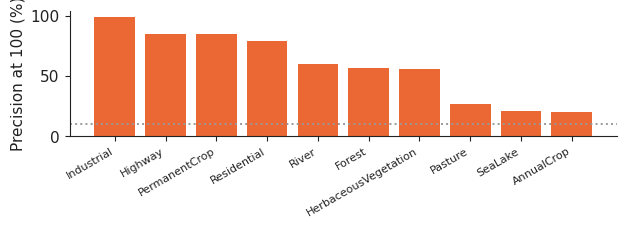

In [3]:
RES = REPO + 'lectures/L14/results/'
Sc = pd.read_csv(RES + 'eurosat_scores_best.csv')
CLS = [c for c in Sc.columns if c != 'true']
prec = {c: float((Sc.sort_values(c, ascending=False).head(100)['true'] == c).mean()) for c in CLS}
show('search.mean', 'mean precision at 100 (%)', round(100 * float(np.mean(list(prec.values()))), 1))
for c in CLS:
    show(f'search.per_class.{c}', f'precision at 100, {c} (%)', round(100 * prec[c], 1))
o = sorted(CLS, key=lambda c: -prec[c])
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.bar(range(10), [100 * prec[c] for c in o], color=PAL['model'])
ax.axhline(10, ls=':', color='#999999')
ax.set_xticks(range(10))
ax.set_xticklabels(o, rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Precision at 100 (%)')
fig.tight_layout()
fig.savefig('text_search.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()